<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    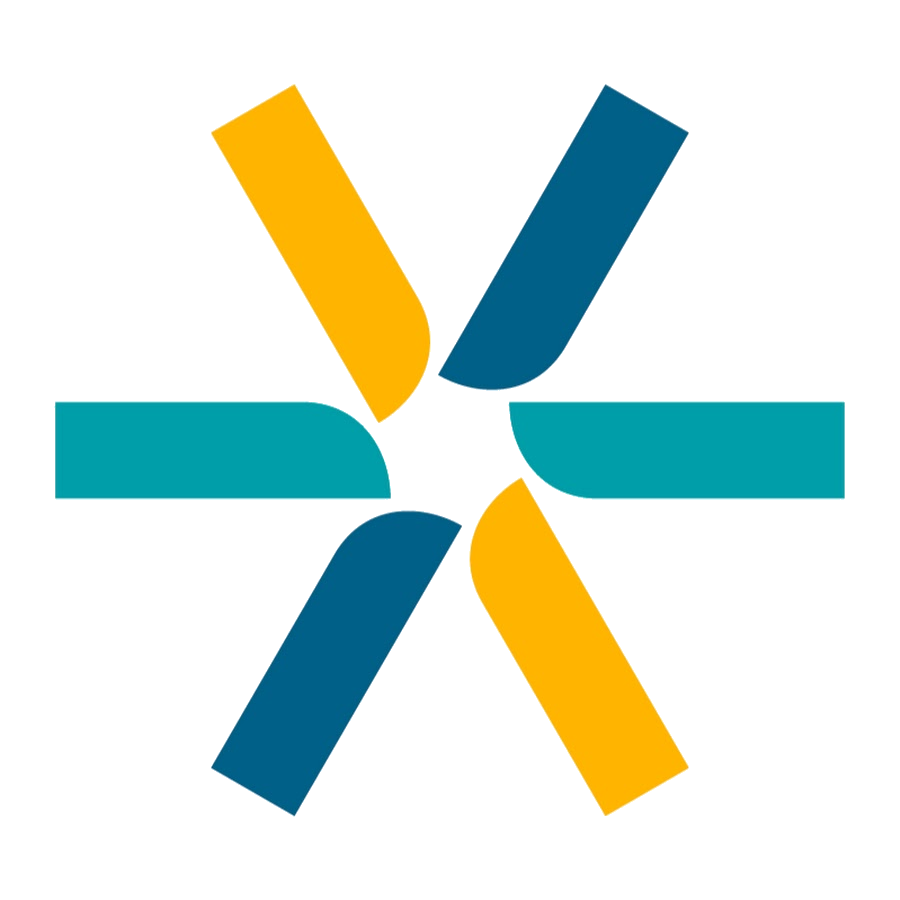
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Ensambles: boosting y apilamiento · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 7 · Corregir en secuencia, y aprender a combinar</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 40 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La misma: ¿la demanda de este agente va a caer más de un 15 % el mes que viene, y con qué probabilidad? La clase 38 entrenó muchos modelos a la vez y los promedió. Esta los entrena uno después de otro, cada uno corrigiendo al anterior (boosting), y al final entrena un modelo que aprende a combinar a los demás (apilamiento).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas filas, predictoras, corte temporal y prueba. Referencias: la logística (AUC ~0,66), los vecinos (~0,74), el árbol (~0,72) y el bosque de la clase 38 (~0,76, log-loss ~0,33). Para la potenciación en regresión, los MWh de las clases 29 y 31, contra la recta (~9 800) y grado 2 + Lasso (~8 300).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">AdaBoost con sus pesos, a mano y contra la biblioteca; la potenciación del gradiente con tres árboles a mano, la tasa, la detención temprana y el submuestreo; las implementaciones rápidas (histogramas, XGBoost); y el apilamiento con sus predicciones limpias.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 40: 1 · datos y referencias → A · AdaBoost → B · gradiente → C · más rápido → D · apilar → E · comparativo → F · usarlo, árbol por árbol.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sobre la prueba, con las seis métricas, contra las referencias. La cantidad de árboles, con detención temprana sobre una validación <b>temporal</b>: el último 20 % del entrenamiento, en el tiempo.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber antes de modelar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Faltantes.</b> Los árboles, los bosques y la potenciación por histogramas aceptan faltantes; <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">AdaBoostClassifier</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GradientBoostingClassifier</code> no. Para esos dos se imputa con la mediana del entrenamiento (y para la aplicación, el imputador va adentro del flujo).</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Ruido y desbalance.</b> AdaBoost sube el peso de las filas que erró. Con un objetivo tan ruidoso, muchas caídas son imposibles de anticipar, y su peso crece sin provecho: es la razón por la que AdaBoost es sensible al ruido, y acá se va a notar.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Validación en el tiempo.</b> Donde la cátedra aparta un 20 % al azar del entrenamiento para parar a tiempo, acá se aparta el último 20 % en el tiempo; y en el apilamiento a mano, las dos mitades son la primera y la segunda mitad del período. <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">StackingClassifier</code> usa pliegues que no respetan el tiempo, y se dice.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>XGBoost</b> es una biblioteca aparte (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">pip install xgboost</code>); si no está, esa celda lo dice y se saltea.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos, y las referencias</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Lo mismo que las clases anteriores, en una celda</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cargar, armar las predictoras, partir por fecha, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">registrar()</code>, las cuatro referencias (con el bosque de la clase 38), la validación temporal para parar a tiempo, y copias imputadas para los dos algoritmos que no aceptan faltantes.</p></div>

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")   # primeros pliegues temporales sin var_hace_un_anio

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
base_lags = demanda[["serie", "periodo", "demanda_MWh"]]
for k in [1, 2, 12, 13]:
    t = base_lags.copy(); t["periodo"] = t["periodo"] + k
    demanda = demanda.merge(t.rename(columns={"demanda_MWh": f"lag{k}"}), on=["serie", "periodo"], how="left")

datos = demanda[demanda["lag1"] > 0].copy()
datos["ratio_dias"] = datos["periodo"].dt.days_in_month / (datos["periodo"] - 1).dt.days_in_month
datos["var_mes_ant"] = pd.Series(np.where(datos["lag2"] > 0, datos["lag1"] / datos["lag2"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["volatilidad"] = datos["var_mes_ant"].abs()
datos["var_hace_un_anio"] = pd.Series(np.where((datos["lag13"] > 0) & (datos["lag12"] >= 0), datos["lag12"] / datos["lag13"] - 1, np.nan), index=datos.index).clip(-1, 3)
datos["log_tamano"] = np.log10(datos["lag1"])
datos["mes_num"] = datos["periodo"].dt.month
datos["es_gran_usuario"] = (datos["categoria_demanda"] == "Gran Usuario").astype(int)
datos["es_residencial"] = (datos["categoria_tarifa"] == "Residencial").astype(int)
UMBRAL_CAIDA = 0.15
datos["cae_fuerte"] = (datos["demanda_MWh"] < (1 - UMBRAL_CAIDA) * datos["lag1"]).astype(int)
datos = datos.sort_values(["periodo", "serie"]).reset_index(drop=True)

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
OBJETIVO = "cae_fuerte"
CORTE = pd.Period("2019-06", freq="M")
ent_mask = datos["periodo"] <= CORTE
X_ent, X_pru = datos.loc[ent_mask, PREDICTORAS], datos.loc[~ent_mask, PREDICTORAS]
y_ent, y_pru = datos.loc[ent_mask, OBJETIVO], datos.loc[~ent_mask, OBJETIVO]
CV = TimeSeriesSplit(n_splits=5)

def preparado(modelo):
    """Imputar, escalar y recién entonces el modelo."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), modelo)

resultados = {}
def guardar(nombre, prob, t_fit, t_pred, modelo, umbral=0.5):
    pred = (prob >= umbral).astype(int)
    resultados[nombre] = {"exactitud": accuracy_score(y_pru, pred), "precisión": precision_score(y_pru, pred, zero_division=0),
                          "exhaustividad": recall_score(y_pru, pred), "F1": f1_score(y_pru, pred), "AUC": roc_auc_score(y_pru, prob),
                          "log-loss": log_loss(y_pru, prob), "ajuste (ms)": t_fit, "predicción (ms)": t_pred, "modelo": modelo}

def registrar(nombre, modelo, umbral=0.5, cols=None):
    cols = PREDICTORAS if cols is None else cols
    t0 = time.perf_counter(); modelo.fit(X_ent[cols], y_ent); t_fit = (time.perf_counter() - t0) * 1000
    t0 = time.perf_counter(); prob = modelo.predict_proba(X_pru[cols])[:, 1]; t_pred = (time.perf_counter() - t0) * 1000
    guardar(nombre, prob, t_fit, t_pred, modelo, umbral)
    return modelo

registrar("línea de base (mayoritaria)", DummyClassifier(strategy="most_frequent"))
logistica = registrar("regresión logística (clase 32)", preparado(LogisticRegression()))
vecinos = registrar("k vecinos, k=101 (clase 34)", preparado(KNeighborsClassifier(n_neighbors=101)))
arbol = registrar("árbol, profundidad 10, mínimo 200 (clase 35)", DecisionTreeClassifier(max_depth=10, min_samples_leaf=200, random_state=2026))
bosque = registrar("bosque, 500 árboles, mínimo 30 (clase 38)", RandomForestClassifier(n_estimators=500, min_samples_leaf=30, random_state=2026, n_jobs=-1))
UMBRAL_ALT = 0.15

# Validación temporal para parar a tiempo: el último 20 % del entrenamiento (los datos están ordenados por período)
corte_v = int(len(X_ent) * 0.8)
X_ent2, X_val, y_ent2, y_val = X_ent.iloc[:corte_v], X_ent.iloc[corte_v:], y_ent.iloc[:corte_v], y_ent.iloc[corte_v:]
print(f"validación temporal: {datos.loc[X_val.index, 'periodo'].min()} a {datos.loc[X_val.index, 'periodo'].max()} ({len(X_val)} filas)")

# Copias imputadas (mediana del entrenamiento) para AdaBoost y GradientBoosting, que no aceptan faltantes
imputador = SimpleImputer(strategy="median").fit(X_ent)
def imputar(X_): return pd.DataFrame(imputador.transform(X_), columns=PREDICTORAS, index=X_.index)
Xi_ent, Xi_pru, Xi_ent2, Xi_val = imputar(X_ent), imputar(X_pru), imputar(X_ent2), imputar(X_val)
print(f"{len(X_ent)} filas de entrenamiento ({y_ent.mean() * 100:.1f} % caídas) · {len(X_pru)} de prueba ({y_pru.sum()} caídas)")
for k in list(resultados)[1:]:
    r = resultados[k]; print(f"Referencia · {k:44s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")

validación temporal: 2018-11 a 2019-06 (6283 filas)
31415 filas de entrenamiento (17.1 % caídas) · 5982 de prueba (759 caídas)
Referencia · regresión logística (clase 32)               AUC 0.663 · log-loss 0.365
Referencia · k vecinos, k=101 (clase 34)                  AUC 0.741 · log-loss 0.343
Referencia · árbol, profundidad 10, mínimo 200 (clase 35) AUC 0.724 · log-loss 0.343
Referencia · bosque, 500 árboles, mínimo 30 (clase 38)    AUC 0.761 · log-loss 0.330


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · En secuencia: AdaBoost</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · El algoritmo, paso a paso, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada fila empieza con peso 1/m; se entrena un tocón (árbol de profundidad 1) con esos pesos; su tasa de error rⱼ es la suma de los pesos de las filas que erró; su peso αⱼ = η · log((1 − rⱼ)/rⱼ); las erradas multiplican su peso por exp(αⱼ) y se normaliza. Diez tocones, sobre las 31 000 filas imputadas, y la comprobación contra <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">AdaBoostClassifier</code>.</p></div>

In [2]:
from sklearn.ensemble import AdaBoostClassifier

m = len(Xi_ent); pesos = np.ones(m) / m; tocones, alfas, pasos = [], [], []
for j in range(10):
    tocon = DecisionTreeClassifier(max_depth=1, random_state=0).fit(Xi_ent, y_ent, sample_weight=pesos)       # 1. entrenar con los pesos
    pred = tocon.predict(Xi_ent); errado = pred != y_ent.to_numpy()
    r = pesos[errado].sum()                                                                                  # 2. tasa de error ponderada
    alfa = 1.0 * np.log((1 - r) / r)                                                                         # 3. peso del predictor (η = 1)
    pesos = pesos * np.exp(alfa * errado); pesos = pesos / pesos.sum()                                       # 4. suben las erradas; normalizar
    tocones.append(tocon); alfas.append(alfa)
    pasos.append({"tocón": j + 1, "pregunta": f"{PREDICTORAS[tocon.tree_.feature[0]]} ≤ {tocon.tree_.threshold[0]:.3g}", "predice «cae» en": int(pred.sum()), "filas erradas": int(errado.sum()),
                  "tasa de error rⱼ (ponderada)": r, "peso αⱼ": alfa, "peso de las caídas (suma)": pesos[y_ent.to_numpy() == 1].sum(), "peso máximo / mínimo": pesos.max() / pesos.min()})
display(pd.DataFrame(pasos).round(4))
ada10 = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=10, learning_rate=1.0, random_state=0).fit(Xi_ent, y_ent)
print(f"La biblioteca, con los mismos diez tocones · tasas de error: {ada10.estimator_errors_.round(3)}")
print(f"                                             pesos αⱼ:       {ada10.estimator_weights_.round(3)}")
print(f"Iguales a los de la cuenta a mano: {np.allclose(ada10.estimator_weights_, alfas)}")
votos = sum(a * np.where(t.predict(Xi_pru) == 1, 1, -1) for a, t in zip(alfas, tocones))
print(f"Predicción a mano (signo de la suma de votos pesados) igual a la de la biblioteca en {int(((votos > 0).astype(int) == ada10.predict(Xi_pru)).sum())} de {len(Xi_pru)} filas")

,tocón,pregunta,predice «cae» en,filas erradas,tasa de error rⱼ (ponderada),peso αⱼ,peso de las caídas (suma),peso máximo / mínimo
0,1,es_residencial ≤ 0.5,0,5380,0.1713,1.5768,0.5000,4.8392
1,2,var_hace_un_anio ≤ -0.00144,24377,20141,0.4290,0.2860,0.4532,6.4415
2,3,volatilidad ≤ 0.0984,16565,14763,0.4256,0.2998,0.4407,8.6934
3,4,es_residencial ≤ 0.5,13411,12665,0.4335,0.2677,0.4427,11.3614
4,5,var_hace_un_anio ≤ -0.138,2141,6095,0.4145,0.3452,0.5127,16.0461
5,6,ratio_dias ≤ 0.984,13835,13427,0.4478,0.2097,0.5148,19.7893
6,7,log_tamano ≤ 3.08,15370,14348,0.4569,0.1730,0.5113,23.5259
7,8,var_mes_ant ≤ 0.652,31415,26035,0.4887,0.0452,0.5000,22.4862
8,9,var_mes_ant ≤ 0.652,1319,5777,0.4843,0.0629,0.5139,23.9469
9,10,var_mes_ant ≤ 0.82,31415,26035,0.4861,0.0558,0.5000,22.6475


La biblioteca, con los mismos diez tocones · tasas de error: [0.171 0.429 0.426 0.433 0.415 0.448 0.457 0.489 0.484 0.486]
                                             pesos αⱼ:       [1.577 0.286 0.3   0.268 0.345 0.21  0.173 0.045 0.063 0.056]
Iguales a los de la cuenta a mano: True
Predicción a mano (signo de la suma de votos pesados) igual a la de la biblioteca en 5982 de 5982 filas


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El primer tocón es la línea de base: con pesos parejos, ninguna pregunta deja una hoja con mayoría de caídas, así que predice «no cae» en todas, se equivoca en todas las caídas (r = 0,17) y aun así pesa bastante, porque acierta el 83 %. Después de su paso las caídas pasan a pesar la mitad del total, y recién el segundo tocón se anima a marcar caídas. Desde ahí, cada tocón trabaja sobre lo que los anteriores no pudieron, y su tasa de error se acerca a 0,5. La cuenta a mano coincide con la biblioteca.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Qué dice el peso</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">αⱼ en función de rⱼ: positivo si acierta más que el azar, cero en 0,5, negativo si acierta menos. Y el predictor perfecto, con iris, como en la cátedra.</p></div>

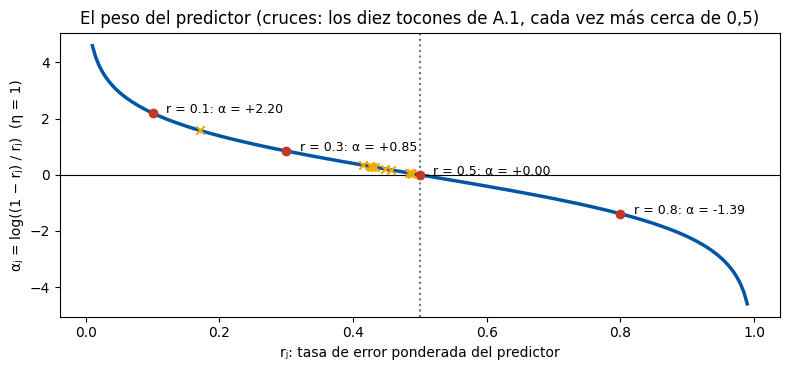

El primer tocón (es_residencial ≤ 0.5) tiene r = 0.171 y α = 1.58; el décimo, r = 0.486 y α = 0.06.
Con un predictor base que acierta todo el entrenamiento (un árbol sin freno sobre iris), la biblioteca entrena 1 de 50: para en el primero, porque un predictor perfecto no deja nada que corregir.


In [3]:
r = np.linspace(0.01, 0.99, 200)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(r, np.log((1 - r) / r), color=AZUL, lw=2.5); ax.axhline(0, color="black", lw=0.8); ax.axvline(0.5, color=GRIS, ls=":")
for rj in [0.1, 0.3, 0.5, 0.8]:
    ax.scatter([rj], [np.log((1 - rj) / rj)], color=ROJO, zorder=5); ax.text(rj + 0.02, np.log((1 - rj) / rj), f"r = {rj}: α = {np.log((1 - rj) / rj):+.2f}", fontsize=9)
for k, (p_, a_) in enumerate(zip(pasos, alfas)):
    ax.scatter([p_["tasa de error rⱼ (ponderada)"]], [a_], color=AMBAR, marker="x", zorder=6)
ax.set_xlabel("rⱼ: tasa de error ponderada del predictor"); ax.set_ylabel("αⱼ = log((1 − rⱼ) / rⱼ)  (η = 1)")
ax.set_title("El peso del predictor (cruces: los diez tocones de A.1, cada vez más cerca de 0,5)")
plt.tight_layout(); plt.show()
print(f"El primer tocón ({pasos[0]['pregunta']}) tiene r = {pasos[0]['tasa de error rⱼ (ponderada)']:.3f} y α = {alfas[0]:.2f}; el décimo, r = {pasos[9]['tasa de error rⱼ (ponderada)']:.3f} y α = {alfas[9]:.2f}.")
from sklearn.datasets import load_iris
iris = load_iris()
perfecto = AdaBoostClassifier(DecisionTreeClassifier(max_depth=None), n_estimators=50, random_state=0).fit(iris.data, iris.target)
print(f"Con un predictor base que acierta todo el entrenamiento (un árbol sin freno sobre iris), la biblioteca entrena {len(perfecto.estimators_)} de 50: para en el primero, porque un predictor perfecto no deja nada que corregir.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cinco seguidos</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cinco tocones consecutivos sobre 400 filas y dos columnas (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code>); el tamaño del punto es su peso. Arriba η = 1, abajo η = 0,5.</p></div>

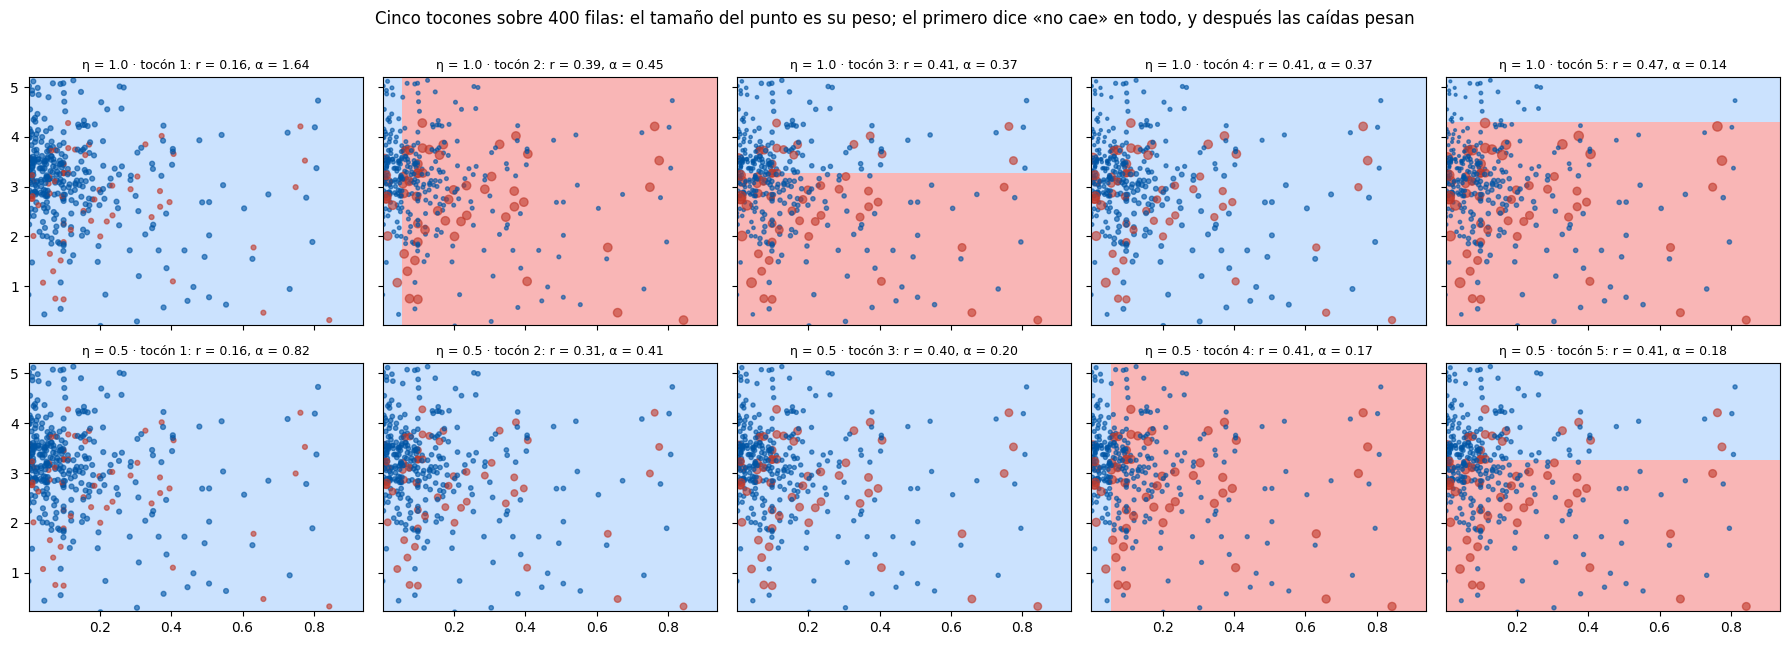

In [4]:
DOS = ["volatilidad", "log_tamano"]
lim1, lim2 = np.percentile(Xi_ent[DOS[0]], [1, 97]), np.percentile(Xi_ent[DOS[1]], [2, 99])
g1, g2 = np.meshgrid(np.linspace(*lim1, 200), np.linspace(*lim2, 200)); grilla = pd.DataFrame(np.c_[g1.ravel(), g2.ravel()], columns=DOS)
muestra = Xi_ent.sample(400, random_state=2026); ym = y_ent.loc[muestra.index]
fig, ejes = plt.subplots(2, 5, figsize=(18, 6.4), sharex=True, sharey=True)
for fila, eta in enumerate([1.0, 0.5]):
    w = np.ones(len(muestra)) / len(muestra)
    for k in range(5):
        t = DecisionTreeClassifier(max_depth=1, random_state=0).fit(muestra[DOS], ym, sample_weight=w)
        err = t.predict(muestra[DOS]) != ym.to_numpy(); rk = w[err].sum(); ak = eta * np.log((1 - rk) / rk)
        ax = ejes[fila, k]
        ax.contourf(g1, g2, t.predict(grilla).reshape(g1.shape), levels=[-0.5, 0.5, 1.5], colors=["#bfdbfe", "#f8a4a4"], alpha=0.8)
        ax.scatter(muestra[DOS[0]], muestra[DOS[1]], s=w * len(muestra) * 12, c=[ROJO if v == 1 else AZUL for v in ym], alpha=0.6)
        ax.set_title(f"η = {eta} · tocón {k + 1}: r = {rk:.2f}, α = {ak:.2f}", fontsize=9); ax.set_xlim(*lim1); ax.set_ylim(*lim2)
        w = w * np.exp(ak * err); w = w / w.sum()
fig.suptitle("Cinco tocones sobre 400 filas: el tamaño del punto es su peso; el primero dice «no cae» en todo, y después las caídas pesan", y=1.0)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · La sentencia, y cuántos predictores</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=30, learning_rate=0.5)</code> registrada (con el imputador adentro del flujo), y el AUC sobre prueba contra la cantidad de predictores con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">staged_predict_proba</code>.</p></div>

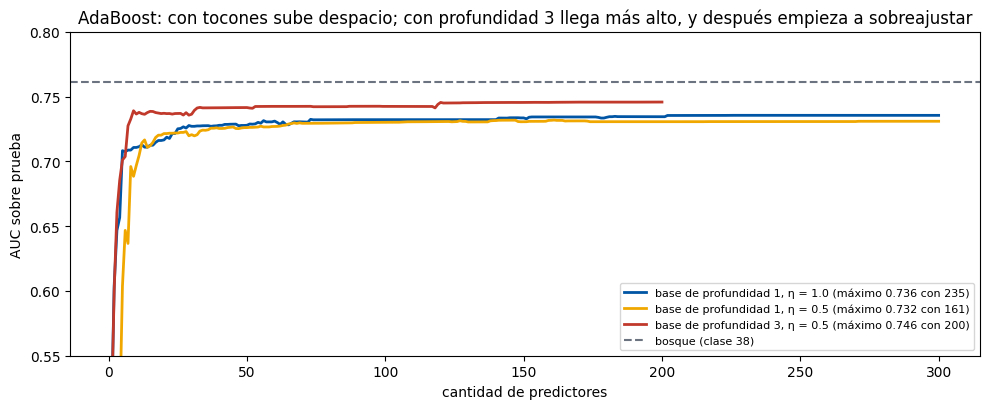

AdaBoost: 30 tocones, η = 0,5                    AUC 0.721 · log-loss 0.380
AdaBoost: 100 árboles de profundidad 3, η = 0,5  AUC 0.742 · log-loss 0.410
bosque, 500 árboles, mínimo 30 (clase 38)        AUC 0.761 · log-loss 0.330


In [5]:
ada30 = registrar("AdaBoost: 30 tocones, η = 0,5", make_pipeline(SimpleImputer(strategy="median"), AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=30, learning_rate=0.5, random_state=2026)))
fig, ax = plt.subplots(figsize=(10, 4.2))
curvas = {}
for base, eta, n, color in [(1, 1.0, 300, AZUL), (1, 0.5, 300, AMBAR), (3, 0.5, 200, ROJO)]:
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=base), n_estimators=n, learning_rate=eta, random_state=2026).fit(Xi_ent, y_ent)
    curva = [roc_auc_score(y_pru, p[:, 1]) for p in ada.staged_predict_proba(Xi_pru)]; curvas[(base, eta)] = curva
    ax.plot(range(1, len(curva) + 1), curva, color=color, lw=2, label=f"base de profundidad {base}, η = {eta} (máximo {max(curva):.3f} con {int(np.argmax(curva)) + 1})")
ax.axhline(resultados["bosque, 500 árboles, mínimo 30 (clase 38)"]["AUC"], color=GRIS, ls="--", label="bosque (clase 38)")
ax.set_xlabel("cantidad de predictores"); ax.set_ylabel("AUC sobre prueba"); ax.set_ylim(0.55, 0.8); ax.legend(fontsize=8)
ax.set_title("AdaBoost: con tocones sube despacio; con profundidad 3 llega más alto, y después empieza a sobreajustar")
plt.tight_layout(); plt.show()
ada3 = registrar("AdaBoost: 100 árboles de profundidad 3, η = 0,5", make_pipeline(SimpleImputer(strategy="median"), AdaBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=100, learning_rate=0.5, random_state=2026)))
for k in ["AdaBoost: 30 tocones, η = 0,5", "AdaBoost: 100 árboles de profundidad 3, η = 0,5", "bosque, 500 árboles, mínimo 30 (clase 38)"]:
    r = resultados[k]; print(f"{k:48s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">AdaBoost ordena razonablemente (cerca de los vecinos con profundidad 3), pero no llega al bosque, y su log-loss es el peor de los ensambles: no promedia probabilidades sino que suma votos pesados, y sus «probabilidades» quedan amontonadas cerca de 0,5. Con un objetivo ruidoso, insistir sobre las filas erradas tiene un techo: muchas de ellas son caídas que nada en los datos anticipa.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Sobre residuos: la potenciación del gradiente</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · Tres árboles a mano: la demanda en MWh</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La diapositiva «tres árboles a mano» sobre el problema de las clases 29 y 31: un árbol de regresión de profundidad 2 con y; otro con el residuo y₂ = y − h₁(X); un tercero con y₃; para predecir, se suman. Y la comprobación contra <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GradientBoostingRegressor(n_estimators=3, learning_rate=1.0, max_depth=2)</code>. Los faltantes de <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">lag12</code> se imputan.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Un detalle de estos datos:</b> sin mínimo por hoja, el segundo árbol termina en un nodo de cinco distribuidoras gigantes donde dos cortes distintos dan exactamente la misma impureza, y la biblioteca y la cuenta a mano desempatan distinto (cada una con su sorteo de columnas). Sobre el entrenamiento dan lo mismo; sobre prueba, un agente gigante cae de un lado o del otro. Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">min_samples_leaf=20</code> en los dos, esos nodos diminutos no existen y la comprobación es exacta.</p></div>

RMSE sobre prueba · un árbol 28,545 · dos sumados 21,763 · tres sumados 20,537 · la biblioteca con 3 árboles y tasa 1: 20,537 MWh
Las predicciones a mano y las de la biblioteca son iguales: True (diferencia máxima 2.3e-10)
Referencias: la recta de la clase 29 9,825 · copiar el mes anterior 10,463 · grado 2 + Lasso (clase 31) ~8.300 MWh


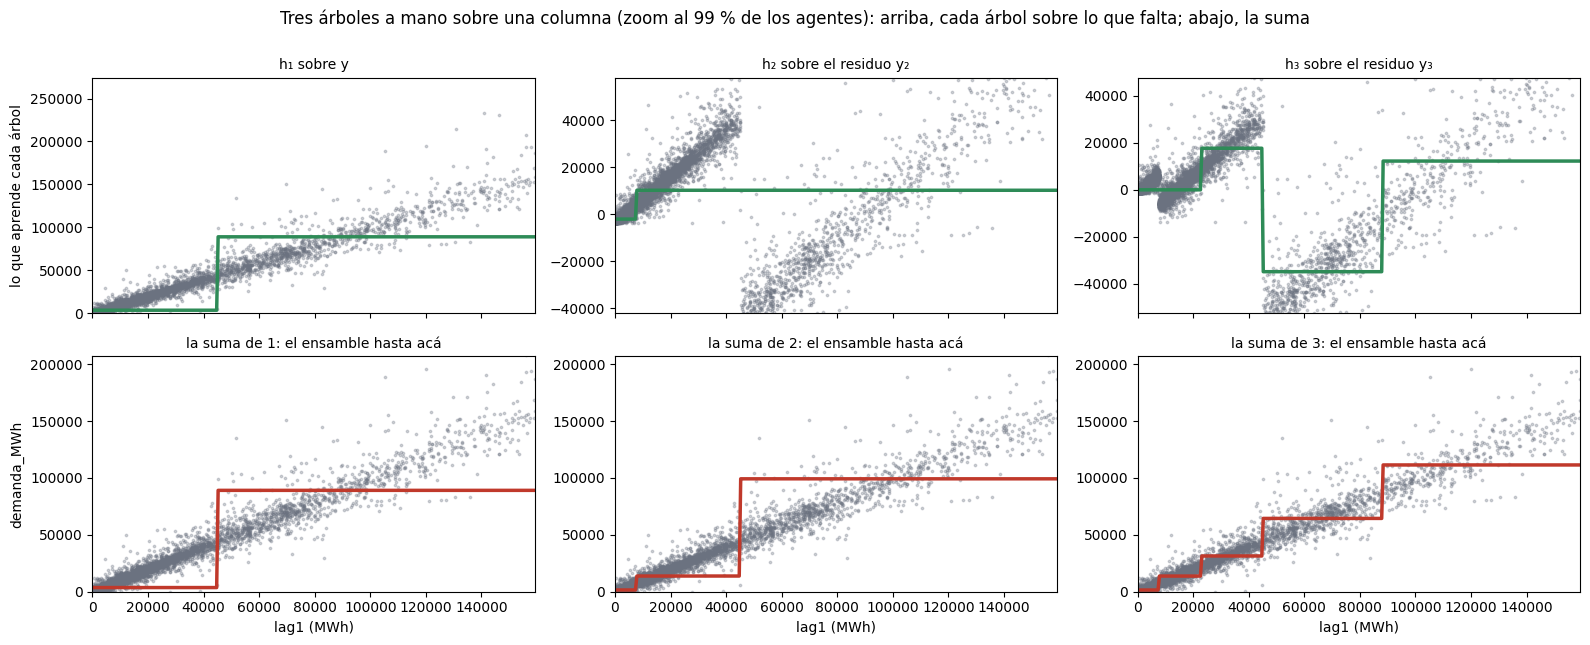

In [6]:
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier

reg = demanda[demanda["lag1"].notna()].copy()
reg["mes_num"] = reg["periodo"].dt.month
reg["es_gran_usuario"] = (reg["categoria_demanda"] == "Gran Usuario").astype(int)
reg["es_residencial"] = (reg["categoria_tarifa"] == "Residencial").astype(int)
P29 = ["lag1", "lag2", "lag12", "mes_num", "es_gran_usuario", "es_residencial"]
reg = reg.sort_values(["periodo", "serie"]).reset_index(drop=True)
r_ent = reg["periodo"] <= CORTE
imp_r = SimpleImputer(strategy="median").fit(reg.loc[r_ent, P29])
R_ent, R_pru = pd.DataFrame(imp_r.transform(reg.loc[r_ent, P29]), columns=P29), pd.DataFrame(imp_r.transform(reg.loc[~r_ent, P29]), columns=P29)
t_ent, t_pru = reg.loc[r_ent, "demanda_MWh"].to_numpy(), reg.loc[~r_ent, "demanda_MWh"].to_numpy()
def rmse(a, b): return np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def arbolito(): return DecisionTreeRegressor(max_depth=2, min_samples_leaf=20, random_state=2026)   # mínimo 20 por hoja: ver la caja
h1 = arbolito().fit(R_ent, t_ent)                                                          # 1. el primero, con y
y2 = t_ent - h1.predict(R_ent)                                                              # 2. el residuo que dejó
h2 = arbolito().fit(R_ent, y2)
y3 = y2 - h2.predict(R_ent)                                                                 # 3. lo que todavía falta
h3 = arbolito().fit(R_ent, y3)
a_mano = h1.predict(R_pru) + h2.predict(R_pru) + h3.predict(R_pru)                          # 4. predecir: sumar
gb3 = GradientBoostingRegressor(n_estimators=3, learning_rate=1.0, max_depth=2, min_samples_leaf=20, random_state=2026).fit(R_ent, t_ent)
print(f"RMSE sobre prueba · un árbol {rmse(t_pru, h1.predict(R_pru)):,.0f} · dos sumados {rmse(t_pru, h1.predict(R_pru) + h2.predict(R_pru)):,.0f} · tres sumados {rmse(t_pru, a_mano):,.0f} · la biblioteca con 3 árboles y tasa 1: {rmse(t_pru, gb3.predict(R_pru)):,.0f} MWh")
print(f"Las predicciones a mano y las de la biblioteca son iguales: {np.allclose(a_mano, gb3.predict(R_pru))} (diferencia máxima {np.abs(a_mano - gb3.predict(R_pru)).max():.1e})")
from sklearn.linear_model import LinearRegression
recta29 = make_pipeline(StandardScaler(), LinearRegression()).fit(R_ent, t_ent)
print(f"Referencias: la recta de la clase 29 {rmse(t_pru, recta29.predict(R_pru)):,.0f} · copiar el mes anterior {rmse(t_pru, R_pru['lag1']):,.0f} · grado 2 + Lasso (clase 31) ~8.300 MWh")

una = R_ent[["lag1"]]; lim = una["lag1"].quantile(0.99); xs = pd.DataFrame({"lag1": np.linspace(0, una["lag1"].max(), 2000)})
g1_ = DecisionTreeRegressor(max_depth=2, random_state=2026).fit(una, t_ent); res2 = t_ent - g1_.predict(una)
g2_ = DecisionTreeRegressor(max_depth=2, random_state=2026).fit(una, res2); res3 = res2 - g2_.predict(una)
g3_ = DecisionTreeRegressor(max_depth=2, random_state=2026).fit(una, res3)
fig, ejes = plt.subplots(2, 3, figsize=(16, 6.4), sharex=True)
for k, (h, objetivo, suma, nombre) in enumerate([(g1_, t_ent, [g1_], "h₁ sobre y"), (g2_, res2, [g1_, g2_], "h₂ sobre el residuo y₂"), (g3_, res3, [g1_, g2_, g3_], "h₃ sobre el residuo y₃")]):
    ejes[0, k].scatter(una["lag1"], objetivo, s=3, alpha=0.3, color=GRIS); ejes[0, k].plot(xs, h.predict(xs), color=VERDE, lw=2.5); ejes[0, k].set_title(nombre, fontsize=10)
    ejes[0, k].set_xlim(0, lim); ejes[0, k].set_ylim(np.percentile(objetivo, 0.5), np.percentile(objetivo, 99.5))
    ejes[1, k].scatter(una["lag1"], t_ent, s=3, alpha=0.3, color=GRIS); ejes[1, k].plot(xs, sum(h_.predict(xs) for h_ in suma), color=ROJO, lw=2.5)
    ejes[1, k].set_title(f"la suma de {k + 1}: el ensamble hasta acá", fontsize=10); ejes[1, k].set_xlabel("lag1 (MWh)"); ejes[1, k].set_ylim(0, 1.3 * lim)
ejes[0, 0].set_ylabel("lo que aprende cada árbol"); ejes[1, 0].set_ylabel("demanda_MWh")
fig.suptitle("Tres árboles a mano sobre una columna (zoom al 99 % de los agentes): arriba, cada árbol sobre lo que falta; abajo, la suma", y=1.0)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada árbol se entrena sobre lo que el anterior dejó, y la suma va acomodándose a la diagonal con escalones. Con tres árboles de profundidad 2 hay como mucho 4 × 3 escalones: la escalera todavía está lejos de una recta, y el error lo dominan los agentes gigantes. La comprobación con la biblioteca da las mismas predicciones.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · La tasa de aprendizaje</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">learning_rate</code> escala la contribución de cada árbol. La figura sobre una columna, y la tabla sobre las seis: el RMSE de prueba para cada tasa y cantidad de árboles. Para no entrenar veinte modelos, se entrena uno por tasa con 500 árboles y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">staged_predict</code> da el error después de cada uno.</p></div>

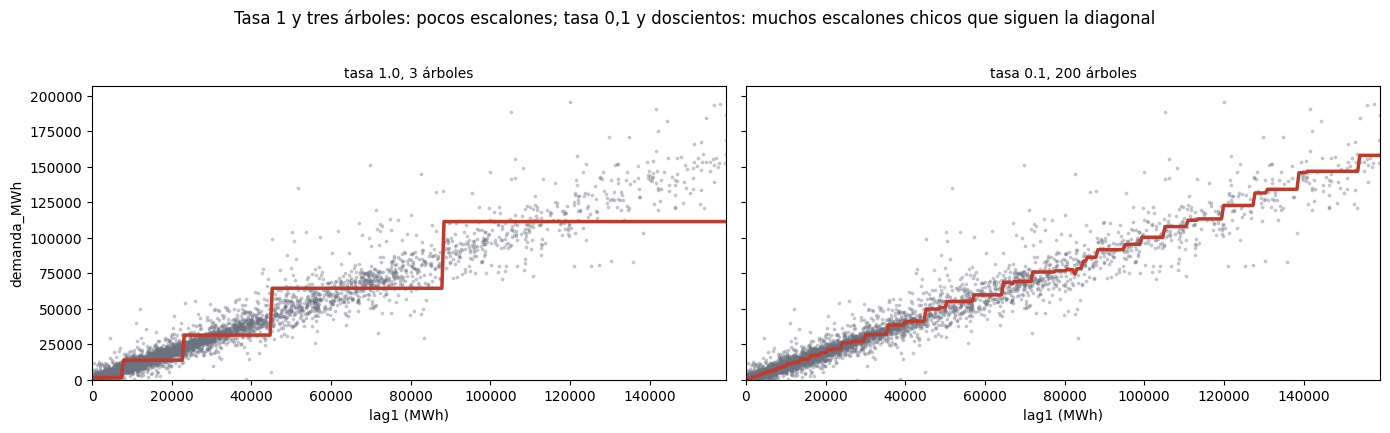

RMSE prueba                                     RMSE entrenamiento                                 
árboles         3        10       50       200      500                3        10      50      200     500
tasa                                                                                                       
0.05        59903.0  47716.0  17895.0  13345.0  13724.0            36481.0  27060.0  8111.0  4883.0  4065.0
0.10        53701.0  35131.0  13455.0  13929.0  13944.0            31821.0  17988.0  5675.0  4291.0  3309.0
0.30        33927.0  13219.0  14204.0  14670.0  14760.0            18082.0   6852.0  4824.0  3208.0  2355.0
1.00        16853.0  14921.0  15066.0  14711.0  14798.0            10296.0   6489.0  3807.0  2309.0  1479.0

Mejor sobre prueba: tasa 0.3, 10 árboles, RMSE 13,219 MWh (la recta: 9,825)


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (eta, n) in zip(ejes, [(1.0, 3), (0.1, 200)]):
    g = GradientBoostingRegressor(n_estimators=n, learning_rate=eta, max_depth=2, random_state=2026).fit(una, t_ent)
    ax.scatter(una["lag1"], t_ent, s=3, alpha=0.3, color=GRIS); ax.plot(xs, g.predict(xs), color=ROJO, lw=2.5)
    ax.set_xlim(0, lim); ax.set_ylim(0, 1.3 * lim); ax.set_title(f"tasa {eta}, {n} árboles", fontsize=10); ax.set_xlabel("lag1 (MWh)")
ejes[0].set_ylabel("demanda_MWh")
fig.suptitle("Tasa 1 y tres árboles: pocos escalones; tasa 0,1 y doscientos: muchos escalones chicos que siguen la diagonal", y=1.02)
plt.tight_layout(); plt.show()
CANTIDADES = [3, 10, 50, 200, 500]; filas = []
for eta in [1.0, 0.3, 0.1, 0.05]:
    g = GradientBoostingRegressor(n_estimators=500, learning_rate=eta, max_depth=2, random_state=2026).fit(R_ent, t_ent)
    for n, (p_e, p_p) in enumerate(zip(g.staged_predict(R_ent), g.staged_predict(R_pru)), start=1):
        if n in CANTIDADES: filas.append({"tasa": eta, "árboles": n, "RMSE entrenamiento": rmse(t_ent, p_e), "RMSE prueba": rmse(t_pru, p_p)})
tabla_eta = pd.DataFrame(filas)
display(tabla_eta.pivot(index="tasa", columns="árboles", values=["RMSE prueba", "RMSE entrenamiento"]).round(0))
mejor = tabla_eta.loc[tabla_eta["RMSE prueba"].idxmin()]
print(f"Mejor sobre prueba: tasa {mejor['tasa']}, {int(mejor['árboles'])} árboles, RMSE {mejor['RMSE prueba']:,.0f} MWh (la recta: {rmse(t_pru, recta29.predict(R_pru)):,.0f})")

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Más árboles o más tasa bajan siempre el error de entrenamiento; el de prueba se estanca muy arriba del de la recta. Es la misma pared que encontraron los vecinos y el árbol: la potenciación también es una suma de escaleras, y una escalera no extrapola a los agentes más grandes que los del entrenamiento. La sección siguiente prueba una salida.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · Detención temprana, y potenciar sobre el cambio</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cuántos árboles, con la validación temporal (el último 20 % del entrenamiento): <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">staged_predict</code> y el mínimo. Después, con la biblioteca: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">n_iter_no_change=10</code>. Y un cambio que no está en la cátedra pero sale de la clase 29: en vez de pedirle a los árboles los MWh, pedirles el <b>cambio</b> respecto del mes anterior (y − lag1). Así no tienen que reproducir la diagonal; solo la corrección.</p></div>

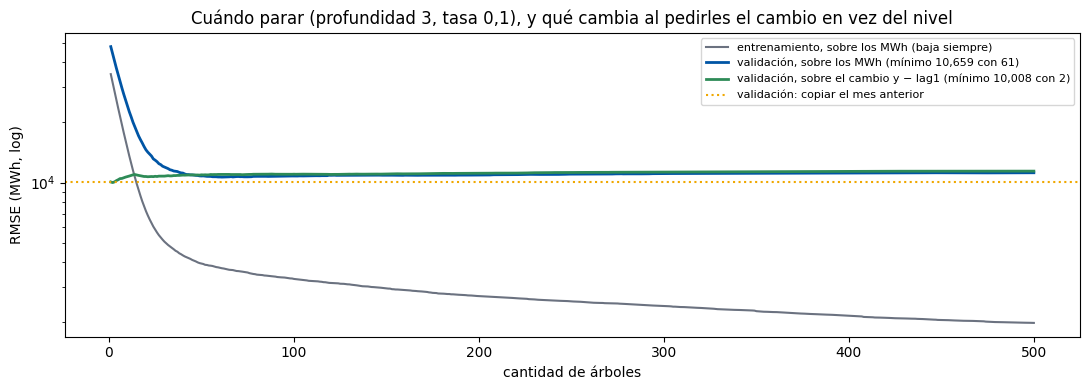

Reentrenados con todo el entrenamiento · sobre los MWh (61 árboles): RMSE prueba 13,640 · sobre el cambio (2 árboles): 9,969 · la recta 9,825
Con n_iter_no_change=10, tasa 0.1 y profundidad 3: paró en 51 árboles de 500 · RMSE prueba 13,961
Con n_iter_no_change=10, tasa 0.05 y profundidad 2: paró en 110 árboles de 500 · RMSE prueba 13,425
Con n_iter_no_change=10, tasa 1.0 y profundidad 2: paró en 89 árboles de 500 · RMSE prueba 17,382


In [8]:
corte_r = int(r_ent.sum() * 0.8)
R_e2, R_val, t_e2, t_val = R_ent.iloc[:corte_r], R_ent.iloc[corte_r:], t_ent[:corte_r], t_ent[corte_r:]
g = GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=2026).fit(R_e2, t_e2)
errores_val = [rmse(t_val, p) for p in g.staged_predict(R_val)]; errores_ent = [rmse(t_e2, p) for p in g.staged_predict(R_e2)]
mejor_n = int(np.argmin(errores_val)) + 1
# Potenciar sobre el cambio: el objetivo es y − lag1, y la predicción es lag1 + lo que digan los árboles
gd = GradientBoostingRegressor(n_estimators=500, learning_rate=0.1, max_depth=3, random_state=2026).fit(R_e2, t_e2 - R_e2["lag1"])
errores_val_d = [rmse(t_val, R_val["lag1"] + p) for p in gd.staged_predict(R_val)]
mejor_nd = int(np.argmin(errores_val_d)) + 1
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(1, 501), errores_ent, color=GRIS, label="entrenamiento, sobre los MWh (baja siempre)"); ax.plot(range(1, 501), errores_val, color=AZUL, lw=2, label=f"validación, sobre los MWh (mínimo {min(errores_val):,.0f} con {mejor_n})")
ax.plot(range(1, 501), errores_val_d, color=VERDE, lw=2, label=f"validación, sobre el cambio y − lag1 (mínimo {min(errores_val_d):,.0f} con {mejor_nd})")
ax.axhline(rmse(t_val, R_val["lag1"]), color=AMBAR, ls=":", label="validación: copiar el mes anterior")
ax.set_yscale("log"); ax.set_xlabel("cantidad de árboles"); ax.set_ylabel("RMSE (MWh, log)"); ax.legend(fontsize=8)
ax.set_title("Cuándo parar (profundidad 3, tasa 0,1), y qué cambia al pedirles el cambio en vez del nivel")
plt.tight_layout(); plt.show()
gb_mejor = GradientBoostingRegressor(n_estimators=mejor_n, learning_rate=0.1, max_depth=3, random_state=2026).fit(R_ent, t_ent)
gd_mejor = GradientBoostingRegressor(n_estimators=mejor_nd, learning_rate=0.1, max_depth=3, random_state=2026).fit(R_ent, t_ent - R_ent["lag1"])
print(f"Reentrenados con todo el entrenamiento · sobre los MWh ({mejor_n} árboles): RMSE prueba {rmse(t_pru, gb_mejor.predict(R_pru)):,.0f} · "
      f"sobre el cambio ({mejor_nd} árboles): {rmse(t_pru, R_pru['lag1'] + gd_mejor.predict(R_pru)):,.0f} · la recta {rmse(t_pru, recta29.predict(R_pru)):,.0f}")
for eta, d in [(0.1, 3), (0.05, 2), (1.0, 2)]:
    g_auto = GradientBoostingRegressor(n_estimators=500, learning_rate=eta, max_depth=d, n_iter_no_change=10, validation_fraction=0.1, random_state=2026).fit(R_ent, t_ent)
    print(f"Con n_iter_no_change=10, tasa {eta} y profundidad {d}: paró en {g_auto.n_estimators_} árboles de 500 · RMSE prueba {rmse(t_pru, g_auto.predict(R_pru)):,.0f}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre los MWh, la validación toca su mínimo enseguida y el error queda lejos de la recta. Pidiéndoles el cambio, en cambio, los árboles ya no tienen que inventar la diagonal: parten de «lo mismo que el mes pasado» y solo corrigen. El error baja muchísimo y queda en el orden de la recta, con muy pocos árboles: casi todo el trabajo lo hace «lo mismo que el mes pasado». Elegir bien <b>qué</b> se le pide al modelo importa más que cuántos árboles se le dan. (<code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">n_iter_no_change</code> usa una validación al azar, no temporal; se muestra porque es la interfaz de la biblioteca.)</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.4 · Con una parte de las filas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">subsample</code>: cada árbol con una fracción de las filas al azar. Sobre el cambio, con 200 árboles.</p></div>

In [9]:
for sub in [1.0, 0.5, 0.25]:
    t0 = time.perf_counter(); g = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, subsample=sub, random_state=2026).fit(R_ent, t_ent - R_ent["lag1"]); t_fit = (time.perf_counter() - t0) * 1000
    print(f"subsample = {sub:<5} RMSE prueba {rmse(t_pru, R_pru['lag1'] + g.predict(R_pru)):,.0f} · entrenamiento {rmse(t_ent, R_ent['lag1'] + g.predict(R_ent)):,.0f} · ajuste {t_fit:,.0f} ms")

subsample = 1.0   RMSE prueba 12,048 · entrenamiento 3,095 · ajuste 8,587 ms
subsample = 0.5   RMSE prueba 11,727 · entrenamiento 3,296 · ajuste 5,316 ms
subsample = 0.25  RMSE prueba 12,019 · entrenamiento 3,968 · ajuste 3,157 ms


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.5 · Clasificar: la potenciación sobre las caídas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">GradientBoostingClassifier</code> con el log-loss como pérdida. La curva sobre la validación temporal, y el modelo con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">n_iter_no_change=10</code> registrado (con el imputador adentro).</p></div>

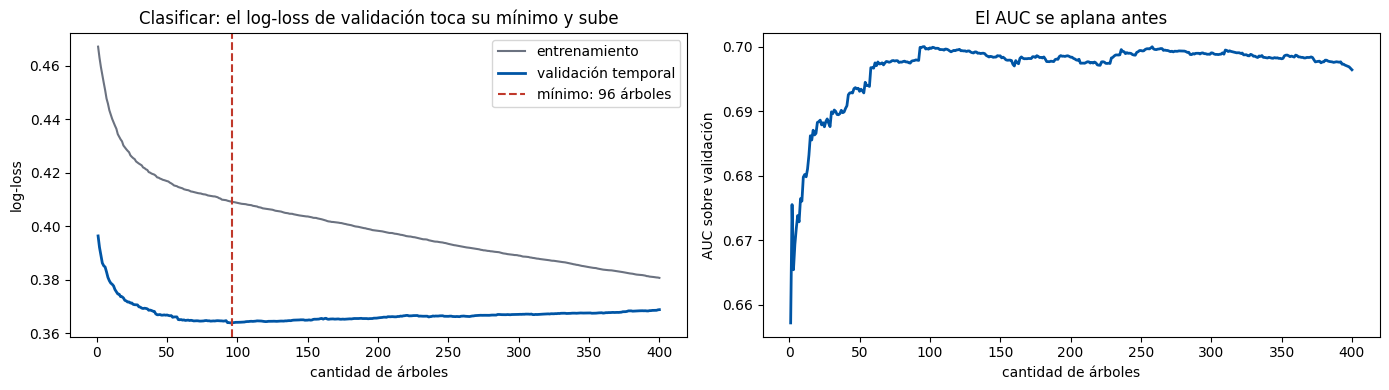

Con n_iter_no_change=10 paró en 143 árboles de 500 · mínimo de la validación temporal: 96
potenciación del gradiente: profundidad 3, tasa 0,1, parada a los 10 AUC 0.753 · log-loss 0.333 · ajuste 12,865 ms
bosque, 500 árboles, mínimo 30 (clase 38)                            AUC 0.761 · log-loss 0.330 · ajuste 3,590 ms
AdaBoost: 100 árboles de profundidad 3, η = 0,5                      AUC 0.742 · log-loss 0.410 · ajuste 6,980 ms


In [10]:
gbc = GradientBoostingClassifier(n_estimators=400, learning_rate=0.1, max_depth=3, random_state=2026).fit(Xi_ent2, y_ent2)
ll_val = [log_loss(y_val, p[:, 1]) for p in gbc.staged_predict_proba(Xi_val)]; ll_ent = [log_loss(y_ent2, p[:, 1]) for p in gbc.staged_predict_proba(Xi_ent2)]
auc_val = [roc_auc_score(y_val, p[:, 1]) for p in gbc.staged_predict_proba(Xi_val)]
mejor_n_c = int(np.argmin(ll_val)) + 1
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
a.plot(range(1, 401), ll_ent, color=GRIS, label="entrenamiento"); a.plot(range(1, 401), ll_val, color=AZUL, lw=2, label="validación temporal"); a.axvline(mejor_n_c, color=ROJO, ls="--", label=f"mínimo: {mejor_n_c} árboles")
a.set_xlabel("cantidad de árboles"); a.set_ylabel("log-loss"); a.legend(); a.set_title("Clasificar: el log-loss de validación toca su mínimo y sube")
b.plot(range(1, 401), auc_val, color=AZUL, lw=2); b.set_xlabel("cantidad de árboles"); b.set_ylabel("AUC sobre validación"); b.set_title("El AUC se aplana antes")
plt.tight_layout(); plt.show()
NOMBRE_GB = "potenciación del gradiente: profundidad 3, tasa 0,1, parada a los 10"
gbc_auto = registrar(NOMBRE_GB, make_pipeline(SimpleImputer(strategy="median"), GradientBoostingClassifier(n_estimators=500, learning_rate=0.1, max_depth=3, n_iter_no_change=10, random_state=2026)))
print(f"Con n_iter_no_change=10 paró en {gbc_auto[-1].n_estimators_} árboles de 500 · mínimo de la validación temporal: {mejor_n_c}")
for k in [NOMBRE_GB, "bosque, 500 árboles, mínimo 30 (clase 38)", "AdaBoost: 100 árboles de profundidad 3, η = 0,5"]:
    r = resultados[k]; print(f"{k:68s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Más rápido: histogramas y XGBoost</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · Por histogramas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">HistGradientBoostingClassifier</code>: agrupa cada columna en hasta 255 bins y busca umbrales entre bins. Acepta faltantes sin imputar. Con más de 10 000 filas la parada temprana se activa sola. Para medir tiempos se repite el entrenamiento cinco veces (157 000 filas, solo para el reloj).</p></div>

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

hgb = registrar("por histogramas: defecto", HistGradientBoostingClassifier(random_state=2026))
hgb_sin = registrar("por histogramas: 100 iteraciones, sin parada", HistGradientBoostingClassifier(early_stopping=False, random_state=2026))
print(f"Iteraciones: {hgb.n_iter_} con el defecto (con {len(X_ent)} filas, la parada temprana está activa) · {hgb_sin.n_iter_} sin parada · bins por columna: hasta {hgb.max_bins}")
for k in [NOMBRE_GB, "por histogramas: defecto", "por histogramas: 100 iteraciones, sin parada"]:
    r = resultados[k]; print(f"{k:68s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")
X_grande, y_grande = pd.concat([Xi_ent] * 5, ignore_index=True), pd.concat([y_ent] * 5, ignore_index=True)
t0 = time.perf_counter(); GradientBoostingClassifier(n_estimators=50, max_depth=3, random_state=2026).fit(X_grande, y_grande); t_gb = time.perf_counter() - t0
t0 = time.perf_counter(); HistGradientBoostingClassifier(max_iter=50, early_stopping=False, random_state=2026).fit(X_grande, y_grande); t_hgb = time.perf_counter() - t0
print(f"Con {len(X_grande):,} filas y 50 árboles: GradientBoosting {t_gb:.1f} s · HistGradientBoosting {t_hgb:.1f} s ({t_gb / t_hgb:.0f} veces más rápido)")

Iteraciones: 57 con el defecto (con 31415 filas, la parada temprana está activa) · 100 sin parada · bins por columna: hasta 255
potenciación del gradiente: profundidad 3, tasa 0,1, parada a los 10 AUC 0.753 · log-loss 0.333 · ajuste 12,865 ms
por histogramas: defecto                                             AUC 0.754 · log-loss 0.334 · ajuste 8,464 ms
por histogramas: 100 iteraciones, sin parada                         AUC 0.753 · log-loss 0.333 · ajuste 461 ms
Con 157,075 filas y 50 árboles: GradientBoosting 11.3 s · HistGradientBoosting 0.6 s (18 veces más rápido)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · Categóricas y faltantes, sin más</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El CSV trae columnas de texto que ninguna clase anterior usó: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">region</code>, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">tipo_agente</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">categoria_tarifa</code>. Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">OrdinalEncoder</code> y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">categorical_features</code> entran directo, junto con los faltantes, sin imputar ni escalar.</p></div>

In [12]:
from sklearn.preprocessing import OrdinalEncoder

CATEGORICAS = ["region", "tipo_agente", "categoria_tarifa"]
codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan).fit(datos.loc[ent_mask, CATEGORICAS])   # una categoría que aparece recién en la prueba queda como faltante
Xc = datos[PREDICTORAS + CATEGORICAS].copy()
Xc[CATEGORICAS] = codificador.transform(Xc[CATEGORICAS])
nuevas = {c_: sorted(set(datos.loc[~ent_mask, c_]) - set(datos.loc[ent_mask, c_])) for c_ in CATEGORICAS}
print("Categorías que aparecen recién en la prueba (quedan como faltantes):", {k: v for k, v in nuevas.items() if v})
print("Categorías:", {col: list(cats) for col, cats in zip(CATEGORICAS, codificador.categories_)})
Xc_ent, Xc_pru = Xc.loc[ent_mask], Xc.loc[~ent_mask]
hgb_c = HistGradientBoostingClassifier(categorical_features=[Xc.columns.get_loc(c_) for c_ in CATEGORICAS], random_state=2026).fit(Xc_ent, y_ent)
p_c = hgb_c.predict_proba(Xc_pru)[:, 1]
print(f"Faltantes en las entradas: {int(Xc_ent.isna().sum().sum()):,} · AUC sobre prueba · ocho predictoras: {resultados['por histogramas: defecto']['AUC']:.3f} · con las tres categóricas: {roc_auc_score(y_pru, p_c):.3f} · log-loss {log_loss(y_pru, p_c):.3f}")

Categorías que aparecen recién en la prueba (quedan como faltantes): {'tipo_agente': ['AR']}
Categorías: {'region': ['BUENOS AIRES', 'CENTRO', 'COMAHUE', 'CUYO', 'GRAN BS.AS.', 'LITORAL', 'NORESTE', 'NOROESTE', 'PATAGONICA'], 'tipo_agente': ['AG', 'DI', 'GU'], 'categoria_tarifa': ['Comercial', 'Industrial/Comercial Grande', 'Mercado a Término', 'Residencial']}
Faltantes en las entradas: 20,609 · AUC sobre prueba · ocho predictoras: 0.754 · con las tres categóricas: 0.755 · log-loss 0.332


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La región y el tipo de agente casi no agregan: lo que dicen ya estaba en las predictoras (el tamaño, la tarifa, la volatilidad). Vale como demostración de la interfaz: con histogramas, un conjunto con texto y faltantes entra sin preparar nada.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · XGBoost</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Biblioteca aparte, interfaz de scikit-learn, parada con un conjunto de evaluación (acá, la validación temporal). Si no está instalada, la celda lo dice.</p></div>

In [13]:
try:
    import xgboost
    xgb = xgboost.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=3, early_stopping_rounds=20, random_state=2026, verbosity=0)
    t0 = time.perf_counter(); xgb.fit(X_ent2, y_ent2, eval_set=[(X_val, y_val)], verbose=False); t_fit = (time.perf_counter() - t0) * 1000
    prob = xgb.predict_proba(X_pru)[:, 1]
    guardar("XGBoost: tasa 0,05, parada a los 20", prob, t_fit, np.nan, xgb)
    r = resultados["XGBoost: tasa 0,05, parada a los 20"]
    print(f"XGBoost {xgboost.__version__} · mejor iteración {xgb.best_iteration} de 1000 · AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {t_fit:,.0f} ms (con los faltantes como están: missing = nan)")
    print("Lo que agrega, con sus defectos: reg_alpha = 0 (ℓ1 sobre las hojas) · reg_lambda = 1 (ℓ2) · gamma = 0 (ganancia mínima para partir) · colsample_bytree = 1 · subsample = 1")
except ImportError:
    print("XGBoost no está instalado: pip install xgboost. La celda se saltea; el resto del cuaderno no la necesita.")

XGBoost 3.4.0 · mejor iteración 194 de 1000 · AUC 0.758 · log-loss 0.331 · ajuste 960 ms (con los faltantes como están: missing = nan)
Lo que agrega, con sus defectos: reg_alpha = 0 (ℓ1 sobre las hojas) · reg_lambda = 1 (ℓ2) · gamma = 0 (ganancia mínima para partir) · colsample_bytree = 1 · subsample = 1


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Apilar: un mezclador con predicciones limpias</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.1 · Entrenar el mezclador a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El entrenamiento se divide en dos <b>en el tiempo</b>: la primera mitad del período y la segunda. La primera capa (logística, bosque, vecinos) se entrena con la primera; predice la segunda (predicciones limpias, y además del «futuro»); el mezclador (una logística) se entrena con esas tres predicciones. Y la contraprueba: el mismo mezclador con predicciones sobre filas que la capa sí vio. El bosque, con 200 árboles para que no tarde.</p></div>

In [14]:
mitad = len(X_ent) // 2
X_a, X_b, y_a, y_b = X_ent.iloc[:mitad], X_ent.iloc[mitad:], y_ent.iloc[:mitad], y_ent.iloc[mitad:]
primera_capa = {"logística": preparado(LogisticRegression()), "bosque": RandomForestClassifier(n_estimators=200, min_samples_leaf=30, random_state=2026, n_jobs=-1), "vecinos": preparado(KNeighborsClassifier(n_neighbors=101))}
for modelo_c in primera_capa.values(): modelo_c.fit(X_a, y_a)
limpias = pd.DataFrame({n: m_.predict_proba(X_b)[:, 1] for n, m_ in primera_capa.items()}, index=X_b.index)
mezclador = LogisticRegression().fit(limpias, y_b)
entradas_prueba = pd.DataFrame({n: m_.predict_proba(X_pru)[:, 1] for n, m_ in primera_capa.items()}, index=X_pru.index)
prob_apilado = mezclador.predict_proba(entradas_prueba)[:, 1]
print(f"Primera mitad: {datos.loc[X_a.index, 'periodo'].min()} a {datos.loc[X_a.index, 'periodo'].max()} · segunda: {datos.loc[X_b.index, 'periodo'].min()} a {datos.loc[X_b.index, 'periodo'].max()}")
print("Lo que ve el mezclador (cinco filas de la segunda mitad):"); display(limpias.head().round(3).assign(real=y_b.head().values))
print(f"Coeficientes del mezclador: {dict(zip(primera_capa, mezclador.coef_[0].round(2)))} · intercepto {mezclador.intercept_[0]:.2f}")
print(f"Apilado a mano, sobre prueba: AUC {roc_auc_score(y_pru, prob_apilado):.3f} · log-loss {log_loss(y_pru, prob_apilado):.3f}   (cada integrante solo, entrenado con la primera mitad: " + " · ".join(f"{n} {roc_auc_score(y_pru, entradas_prueba[n]):.3f}" for n in primera_capa) + ")")
sucias = pd.DataFrame({n: m_.predict_proba(X_a)[:, 1] for n, m_ in primera_capa.items()}, index=X_a.index)
mezclador_sucio = LogisticRegression().fit(sucias, y_a)
p_sucio = mezclador_sucio.predict_proba(entradas_prueba)[:, 1]
print(f"Contraprueba, mezclador con predicciones NO limpias: coeficientes {dict(zip(primera_capa, mezclador_sucio.coef_[0].round(2)))} · prueba AUC {roc_auc_score(y_pru, p_sucio):.3f} · log-loss {log_loss(y_pru, p_sucio):.3f}")
print(f"Sobre las filas que vio, el bosque ordena casi perfecto: AUC {roc_auc_score(y_a, sucias['bosque']):.3f} (contra {roc_auc_score(y_b, limpias['bosque']):.3f} sobre la segunda mitad)")

Primera mitad: 2017-02 a 2018-03 · segunda: 2018-03 a 2019-06
Lo que ve el mezclador (cinco filas de la segunda mitad):


,logística,bosque,vecinos,real
15707,0.278,0.489,0.465,0
15708,0.150,0.212,0.139,0
15709,0.161,0.262,0.327,1
15710,0.182,0.245,0.287,0
15711,0.170,0.298,0.337,1


Coeficientes del mezclador: {'logística': np.float64(1.09), 'bosque': np.float64(6.73), 'vecinos': np.float64(-0.63)} · intercepto -2.99
Apilado a mano, sobre prueba: AUC 0.748 · log-loss 0.340   (cada integrante solo, entrenado con la primera mitad: logística 0.645 · bosque 0.751 · vecinos 0.692)
Contraprueba, mezclador con predicciones NO limpias: coeficientes {'logística': np.float64(-2.71), 'bosque': np.float64(12.89), 'vecinos': np.float64(-2.06)} · prueba AUC 0.749 · log-loss 0.335
Sobre las filas que vio, el bosque ordena casi perfecto: AUC 0.800 (contra 0.704 sobre la segunda mitad)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con predicciones limpias, el mezclador le da al bosque el peso mayor y casi ignora a los vecinos, que entrenados con la mitad del período rinden poco. Con predicciones sucias el bosque parece mucho mejor de lo que es (sobre las filas que vio ordena muy por encima de lo que logra en la segunda mitad), y el mezclador le duplica el peso y castiga a los otros dos con pesos negativos. Acá el daño en prueba no aparece, igual que en la cátedra: el bosque es de verdad el mejor integrante y confiar más en él no cuesta. Con un integrante que memorice más (un bosque sin freno, un árbol de una hoja por fila), el mezclador sucio quedaría atado a él. Las predicciones limpias no son un detalle: son el método.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.2 · La sentencia: StackingClassifier</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">StackingClassifier([...], cv=5)</code>: con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">cv=5</code> cada integrante se entrena cinco veces para predecir limpio cada quinto, y una vez más con todo. Los pliegues son bloques contiguos (sin barajar), pero no respetan el tiempo: para predecir el primer bloque se entrena con los cuatro posteriores. Se registra con mezclador logístico, y la votación blanda de los mismos tres para comparar.</p></div>

In [15]:
from sklearn.ensemble import StackingClassifier, VotingClassifier

integrantes = [("logística", preparado(LogisticRegression())), ("bosque", RandomForestClassifier(n_estimators=200, min_samples_leaf=30, random_state=2026, n_jobs=-1)), ("vecinos", preparado(KNeighborsClassifier(n_neighbors=101)))]
NOMBRE_APILADO = "apilado: logística + bosque + vecinos, mezclador logístico (cv = 5)"
apilado = registrar(NOMBRE_APILADO, StackingClassifier(integrantes, cv=5, n_jobs=-1))
blanda = registrar("votación blanda: logística + bosque + vecinos", VotingClassifier(integrantes, voting="soft", n_jobs=-1))
for k in ["votación blanda: logística + bosque + vecinos", NOMBRE_APILADO, "bosque, 500 árboles, mínimo 30 (clase 38)"]:
    r = resultados[k]; print(f"{k:68s} AUC {r['AUC']:.3f} · log-loss {r['log-loss']:.3f} · ajuste {r['ajuste (ms)']:,.0f} ms")
print(f"Coeficientes del mezclador: {dict(zip([n for n, _ in integrantes], apilado.final_estimator_.coef_[0].round(2)))}")
print(f"Lo que recibe el mezclador para las tres primeras filas de prueba (una columna por integrante): {apilado.transform(X_pru.head(3)).round(3).tolist()}")

votación blanda: logística + bosque + vecinos                        AUC 0.755 · log-loss 0.335 · ajuste 7,051 ms
apilado: logística + bosque + vecinos, mezclador logístico (cv = 5)  AUC 0.758 · log-loss 0.338 · ajuste 25,338 ms
bosque, 500 árboles, mínimo 30 (clase 38)                            AUC 0.761 · log-loss 0.330 · ajuste 3,590 ms
Coeficientes del mezclador: {'logística': np.float64(1.63), 'bosque': np.float64(2.3), 'vecinos': np.float64(2.17)}
Lo que recibe el mezclador para las tres primeras filas de prueba (una columna por integrante): [[0.104, 0.031, 0.01], [0.108, 0.053, 0.02], [0.182, 0.325, 0.267]]


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · El comparativo: cuál resultó mejor, y cómo se elige</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La matriz, el AUC y la decisión</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Todo lo registrado: las referencias, AdaBoost, la potenciación, los histogramas, XGBoost, la votación y el apilado.</p></div>

In [16]:
METRICAS = ["exactitud", "precisión", "exhaustividad", "F1", "AUC", "log-loss", "ajuste (ms)", "predicción (ms)"]
matriz = pd.DataFrame({k: {m_: v[m_] for m_ in METRICAS} for k, v in resultados.items()}).T.astype(float)
(matriz.style.format({m_: "{:.3f}" for m_ in METRICAS[:6]}, na_rep="—").format({"ajuste (ms)": "{:,.0f}", "predicción (ms)": "{:,.0f}"}, na_rep="—")
       .background_gradient(subset=["exactitud", "precisión", "exhaustividad", "F1", "AUC"], cmap="RdYlGn")
       .background_gradient(subset=["log-loss", "ajuste (ms)", "predicción (ms)"], cmap="RdYlGn_r"))

,exactitud,precisión,exhaustividad,F1,AUC,log-loss,ajuste (ms),predicción (ms)
línea de base (mayoritaria),0.873119,0.000000,0.000000,0.000000,0.500000,4.573242,4,1
regresión logística (clase 32),0.873454,0.555556,0.013175,0.025740,0.662507,0.364760,72,4
"k vecinos, k=101 (clase 34)",0.873955,0.600000,0.019763,0.038265,0.741016,0.343047,100,"1,114"
"árbol, profundidad 10, mínimo 200 (clase 35)",0.873287,0.571429,0.005270,0.010444,0.724198,0.343223,151,3
"bosque, 500 árboles, mínimo 30 (clase 38)",0.872785,0.375000,0.003953,0.007823,0.760990,0.329854,"3,590",181
"AdaBoost: 30 tocones, η = 0,5",0.873287,1.000000,0.001318,0.002632,0.720625,0.380178,891,15
"AdaBoost: 100 árboles de profundidad 3, η = 0,5",0.872451,0.484848,0.084321,0.143659,0.742460,0.410301,"6,980",52
"potenciación del gradiente: profundidad 3, tasa 0,1, parada a los 10",0.875794,0.559701,0.098814,0.167973,0.752685,0.333257,"12,865",22
por histogramas: defecto,0.872618,0.487179,0.075099,0.130137,0.754449,0.334110,"8,464",15
"por histogramas: 100 iteraciones, sin parada",0.873287,0.502890,0.114625,0.186695,0.752892,0.333208,461,21


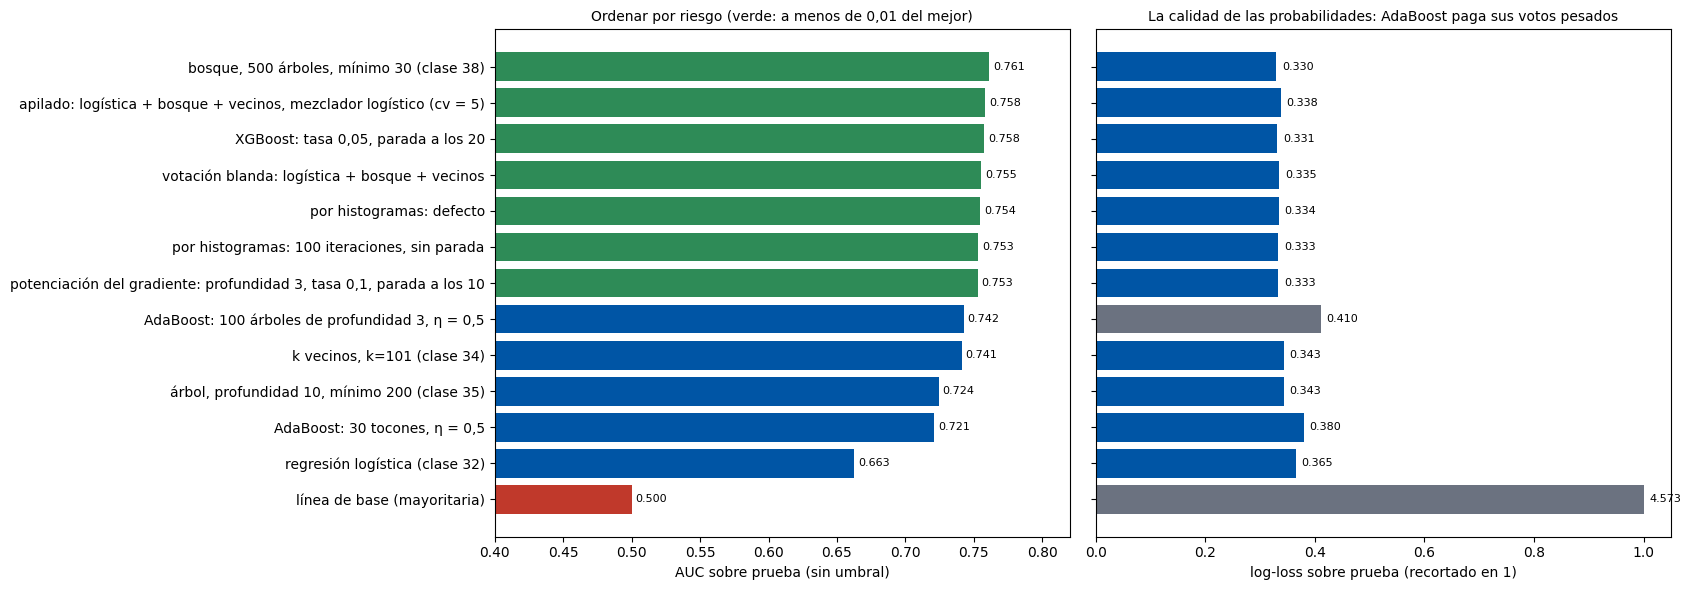

In [17]:
fig, (a, b) = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
orden = matriz.sort_values("AUC", ascending=False)
mejor_auc = orden["AUC"].max()
a.barh(orden.index, orden["AUC"], color=[VERDE if v >= mejor_auc - 0.01 else (ROJO if v < 0.6 else AZUL) for v in orden["AUC"]]); a.invert_yaxis(); a.set_xlim(0.4, 0.82)
for k, v in enumerate(orden["AUC"]): a.text(v + 0.003, k, f"{v:.3f}", va="center", fontsize=8)
a.set_xlabel("AUC sobre prueba (sin umbral)"); a.set_title("Ordenar por riesgo (verde: a menos de 0,01 del mejor)", fontsize=10)
b.barh(orden.index, orden["log-loss"].clip(upper=1.0), color=[AZUL if v < 0.4 else GRIS for v in orden["log-loss"]])
for k, v in enumerate(orden["log-loss"]): b.text(min(v, 1.0) + 0.01, k, f"{v:.3f}", va="center", fontsize=8)
b.set_xlabel("log-loss sobre prueba (recortado en 1)"); b.set_title("La calidad de las probabilidades: AdaBoost paga sus votos pesados", fontsize=10)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Arriba, casi empatados</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">El bosque de la clase 38, la potenciación del gradiente, la de histogramas, XGBoost y el apilado quedan a centésimas entre sí. Ninguno separa claramente: con estas ocho señales débiles, el techo lo pone la información, no el algoritmo.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cuál conviene</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Por histogramas: ordena como los mejores, con buenas probabilidades, entrena en menos de un segundo, acepta faltantes y categóricas sin preparar nada y para solo. El bosque es la alternativa robusta. El apilado entrena la primera capa seis veces para, a lo sumo, empatar.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">AdaBoost</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Ordena aceptable, pero sus probabilidades son las peores de los ensambles: suma votos, no promedia probabilidades. Y con un objetivo ruidoso insiste sobre filas imposibles.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">En regresión</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La potenciación sobre los MWh choca con la misma pared que los vecinos y el árbol; sobre el cambio respecto del mes anterior queda en el orden de la recta. Ahí la lección es elegir bien el objetivo.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">F · Usarlo: cómo se arma la predicción, árbol por árbol</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Dos agentes nuevos: la predicción se construye en secuencia</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los dos agentes de siempre por la potenciación: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">staged_predict_proba</code> da la p̂ después de cada árbol. Arranca en la proporción de caídas (~0,17) y cada árbol corrige un poco. Al lado, el bosque, los histogramas y el apilado.</p></div>

,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,p̂ gradiente,p̂ histogramas,p̂ bosque,p̂ apilado,"entradas del mezclador (logística, bosque, vecinos)"
distribuidora grande · marzo,1.107143,0.02,0.02,0.08,4.903090,3,0,1,0.083,0.041,0.086,0.108,"(0.11, 0.081, 0.149)"
gran usuario chico · febrero,0.903226,0.60,0.60,NaN,2.176091,2,1,0,0.314,0.317,0.314,0.249,"(0.243, 0.301, 0.277)"


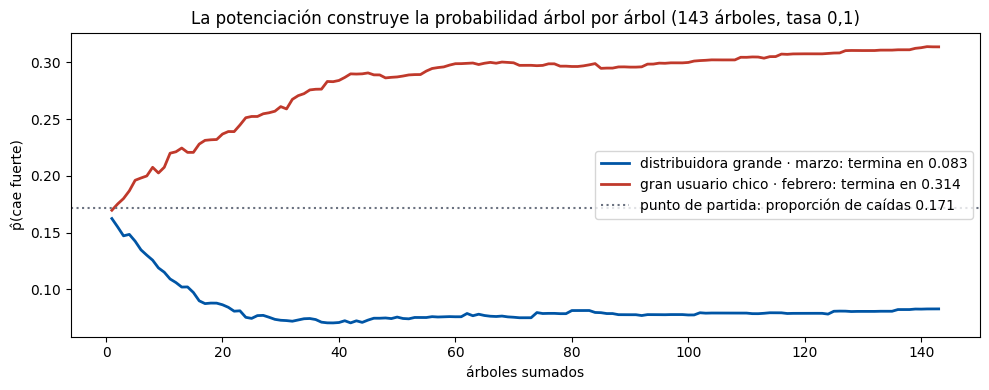

In [18]:
nuevo = pd.DataFrame([
    {"ratio_dias": 31 / 28, "var_mes_ant": 0.02, "volatilidad": 0.02, "var_hace_un_anio": 0.08, "log_tamano": np.log10(80000), "mes_num": 3, "es_gran_usuario": 0, "es_residencial": 1},
    {"ratio_dias": 28 / 31, "var_mes_ant": 0.60, "volatilidad": 0.60, "var_hace_un_anio": np.nan, "log_tamano": np.log10(150), "mes_num": 2, "es_gran_usuario": 1, "es_residencial": 0},
], index=["distribuidora grande · marzo", "gran usuario chico · febrero"])
gb_final = gbc_auto[-1]
trayectoria = np.array([p[:, 1] for p in gb_final.staged_predict_proba(imputar(nuevo[PREDICTORAS]).to_numpy())])
nuevo["p̂ gradiente"] = gbc_auto.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ histogramas"] = hgb.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ bosque"] = bosque.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["p̂ apilado"] = apilado.predict_proba(nuevo[PREDICTORAS])[:, 1].round(3)
nuevo["entradas del mezclador (logística, bosque, vecinos)"] = [tuple(v) for v in apilado.transform(nuevo[PREDICTORAS]).round(3)]
display(nuevo)
fig, ax = plt.subplots(figsize=(10, 4))
for k, color in [(0, AZUL), (1, ROJO)]:
    ax.plot(range(1, len(trayectoria) + 1), trayectoria[:, k], color=color, lw=2, label=f"{nuevo.index[k]}: termina en {trayectoria[-1, k]:.3f}")
ax.axhline(y_ent.mean(), color=GRIS, ls=":", label=f"punto de partida: proporción de caídas {y_ent.mean():.3f}")
ax.set_xlabel("árboles sumados"); ax.set_ylabel("p̂(cae fuerte)"); ax.legend()
ax.set_title(f"La potenciación construye la probabilidad árbol por árbol ({gb_final.n_estimators_} árboles, tasa 0,1)")
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez filas de prueba, por los ensambles</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez filas que cubren el rango de p̂ del apilado: lo que recibió el mezclador, su salida, la potenciación y los histogramas, y lo real. Y la trayectoria de la potenciación para esas diez.</p></div>

In [19]:
prob_ap = apilado.predict_proba(X_pru)[:, 1]
objetivos = np.linspace(prob_ap.min(), prob_ap.max(), 10); elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(prob_ap - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
explicado = X_pru.iloc[elegidos].copy()
explicado.insert(0, "serie", datos.loc[explicado.index, "serie"].str.slice(0, 28).values)
entradas = apilado.transform(X_pru.iloc[elegidos])
for k, nombre in enumerate(["logística", "bosque", "vecinos"]): explicado[f"entrada: {nombre}"] = entradas[:, k].round(3)
explicado["p̂ apilado"] = prob_ap[elegidos].round(3)
explicado["p̂ gradiente"] = gbc_auto.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["p̂ histogramas"] = hgb.predict_proba(X_pru.iloc[elegidos])[:, 1].round(3)
explicado["real"] = y_pru.iloc[elegidos].values
explicado.index.name = "fila"
(explicado.style.format(precision=2)
    .background_gradient(subset=["entrada: logística", "entrada: bosque", "entrada: vecinos", "p̂ apilado", "p̂ gradiente", "p̂ histogramas"], cmap="RdYlGn_r", vmin=0, vmax=0.6)
    .set_caption("Diez filas que cubren el rango de p̂ del apilado: las tres entradas del mezclador, su salida, y las dos potenciaciones"))

,serie,ratio_dias,var_mes_ant,volatilidad,var_hace_un_anio,log_tamano,mes_num,es_gran_usuario,es_residencial,entrada: logística,entrada: bosque,entrada: vecinos,p̂ apilado,p̂ gradiente,p̂ histogramas,real
fila,,,,,,,,,,,,,,,,
31766,EDEABA3D | TARIFA USUARIO NO,1.03,0.02,0.02,0.05,4.99,7,0,0,0.07,0.01,0.00,0.06,0.02,0.02,0
32776,PQCRCRUZ | GUMAS/AUTOGENERAD,1.00,-0.07,0.07,0.39,3.05,8,1,0,0.09,0.13,0.19,0.13,0.07,0.15,1
34403,YPF-P2QY | GUMAS/AUTOGENERAD,1.03,-0.44,0.44,-0.24,1.78,10,1,0,0.20,0.30,0.15,0.19,0.34,0.26,1
32286,CBARILRW | RESIDENCIAL,1.00,0.09,0.09,-0.17,4.11,8,0,1,0.20,0.35,0.26,0.25,0.34,0.43,0
36675,ALPLAVOY | GUMAS/AUTOGENERAD,0.94,-0.05,0.05,-0.30,3.51,2,1,0,0.20,0.38,0.38,0.31,0.33,0.39,0
34912,IRTABAAA | GUMAS/AUTOGENERAD,0.97,3.00,3.00,-0.04,2.51,11,1,0,0.43,0.31,0.40,0.37,0.33,0.22,1
33293,EDENBA1D | RESIDENCIAL,0.97,-0.10,0.10,-0.28,5.07,9,0,1,0.22,0.48,0.49,0.43,0.56,0.86,1
33188,CRAMAL1W | TARIFA BASE ELECT,0.97,2.73,2.73,nan,0.10,9,0,1,0.59,0.40,0.41,0.49,0.53,0.48,0
32784,PRODEBIA | GUMAS/AUTOGENERAD,1.00,2.98,2.98,-0.71,1.33,8,1,0,0.59,0.49,0.45,0.57,0.62,0.51,1


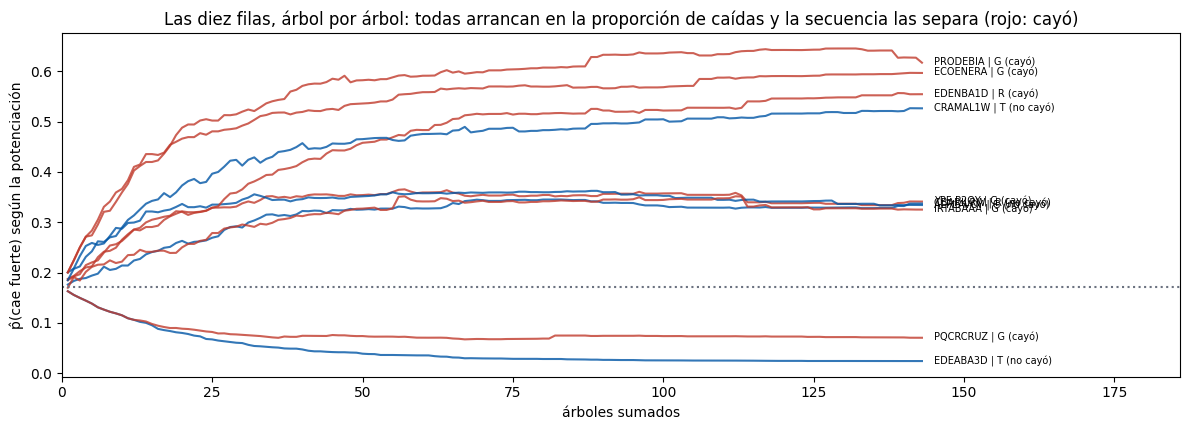

EDEABA3D | TARIFA USUARIO NO (no cayó): el mezclador recibió logística 0.07, bosque 0.01, vecinos 0.00 y devolvió 0.064; la potenciación 0.024, histogramas 0.020.
PQCRCRUZ | GUMAS/AUTOGENERAD (cayó): el mezclador recibió logística 0.09, bosque 0.13, vecinos 0.19 y devolvió 0.126; la potenciación 0.070, histogramas 0.150.
YPF-P2QY | GUMAS/AUTOGENERAD (cayó): el mezclador recibió logística 0.20, bosque 0.30, vecinos 0.15 y devolvió 0.187; la potenciación 0.341, histogramas 0.263.
CBARILRW | RESIDENCIAL (no cayó): el mezclador recibió logística 0.20, bosque 0.35, vecinos 0.26 y devolvió 0.248; la potenciación 0.337, histogramas 0.431.
ALPLAVOY | GUMAS/AUTOGENERAD (no cayó): el mezclador recibió logística 0.20, bosque 0.38, vecinos 0.38 y devolvió 0.311; la potenciación 0.334, histogramas 0.394.
IRTABAAA | GUMAS/AUTOGENERAD (cayó): el mezclador recibió logística 0.43, bosque 0.31, vecinos 0.40 y devolvió 0.371; la potenciación 0.325, histogramas 0.219.
EDENBA1D | RESIDENCIAL (cayó): el mez

In [20]:
tray10 = np.array([p[:, 1] for p in gb_final.staged_predict_proba(Xi_pru.iloc[elegidos].to_numpy())])
fig, ax = plt.subplots(figsize=(12, 4.4))
for k, (fila_id, real) in enumerate(zip(explicado.index, explicado["real"])):
    ax.plot(range(1, len(tray10) + 1), tray10[:, k], color=ROJO if real == 1 else AZUL, lw=1.5, alpha=0.8)
    ax.text(len(tray10) + 2, tray10[-1, k], f"{explicado.loc[fila_id, 'serie'][:12]} ({'cayó' if real == 1 else 'no cayó'})", fontsize=7, va="center")
ax.axhline(y_ent.mean(), color=GRIS, ls=":"); ax.set_xlim(0, len(tray10) * 1.3); ax.set_xlabel("árboles sumados"); ax.set_ylabel("p̂(cae fuerte) según la potenciación")
ax.set_title("Las diez filas, árbol por árbol: todas arrancan en la proporción de caídas y la secuencia las separa (rojo: cayó)")
plt.tight_layout(); plt.show()
for fila_id, j in zip(explicado.index, elegidos):
    real = "cayó" if y_pru.iloc[j] == 1 else "no cayó"
    print(f"{explicado.loc[fila_id, 'serie']} ({real}): el mezclador recibió logística {explicado.loc[fila_id, 'entrada: logística']:.2f}, bosque {explicado.loc[fila_id, 'entrada: bosque']:.2f}, "
          f"vecinos {explicado.loc[fila_id, 'entrada: vecinos']:.2f} y devolvió {explicado.loc[fila_id, 'p̂ apilado']:.3f}; la potenciación {explicado.loc[fila_id, 'p̂ gradiente']:.3f}, histogramas {explicado.loc[fila_id, 'p̂ histogramas']:.3f}.")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La misma predicción, en una aplicación</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Se guardan la potenciación del gradiente (con el imputador adentro del flujo), la de histogramas y el apilado, comprimidos. La app los carga junto con los modelos de las clases 32 a 38 que estén en la carpeta; la potenciación se explica con su trayectoria árbol por árbol, y el apilado con lo que recibe el mezclador y el peso que le da a cada integrante.</p></div>

In [21]:
import joblib

guardar_archivos = {"modelo_cammesa_40_gradiente.joblib": gbc_auto, "modelo_cammesa_40_histogramas.joblib": hgb, "modelo_cammesa_40_apilado.joblib": apilado}
for archivo, modelo_mem in guardar_archivos.items():
    joblib.dump(modelo_mem, archivo, compress=3)
    cargado = joblib.load(archivo)
    print(f"{archivo:38s} mismas probabilidades tras guardar y cargar: {np.allclose(cargado.predict_proba(X_pru), modelo_mem.predict_proba(X_pru))} · {Path(archivo).stat().st_size / 1024:,.0f} KB".replace(",", "."))

modelo_cammesa_40_gradiente.joblib     mismas probabilidades tras guardar y cargar: True · 58 KB
modelo_cammesa_40_histogramas.joblib   mismas probabilidades tras guardar y cargar: True · 98 KB
modelo_cammesa_40_apilado.joblib       mismas probabilidades tras guardar y cargar: True · 6.738 KB


In [22]:
%%writefile app_cammesa_40.py
# Clase 40 sobre CAMMESA · boosting y apilamiento, contra los modelos anteriores · aplicación Streamlit
# Para abrirla, desde la carpeta del cuaderno:  streamlit run app_cammesa_40.py
import calendar
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st

PREDICTORAS = ["ratio_dias", "var_mes_ant", "volatilidad", "var_hace_un_anio", "log_tamano", "mes_num", "es_gran_usuario", "es_residencial"]
AZUL, ROJO, GRIS = "#0055a5", "#c0392b", "#6b7280"
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

st.set_page_config(page_title="¿Va a caer fuerte la demanda?", layout="centered")
st.title("¿La demanda de este agente va a caer fuerte?")
st.caption("Los modelos de las unidades 6 y 7 sobre demanda-ltimos-aos.csv (CAMMESA): logística, vecinos, Bayes, árbol, bosque, potenciación del gradiente, por histogramas y apilado.")

# ---------- 1 · Los modelos guardados por los cuadernos ----------
MODELOS = {
    "regresión logística": ("modelo_cammesa_32.joblib", "Clase_32_regresion_logistica_y_softmax_CAMMESA.ipynb"),
    "k vecinos": ("modelo_cammesa_34_knn.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "Bayes ingenuo": ("modelo_cammesa_34_bayes.joblib", "Clase_34_k_vecinos_y_Bayes_ingenuo_CAMMESA.ipynb"),
    "árbol de decisión": ("modelo_cammesa_35.joblib", "Clase_35_arboles_de_decision_CAMMESA.ipynb"),
    "bosque aleatorio": ("modelo_cammesa_38_bosque.joblib", "Clase_38_ensambles_por_promediado_CAMMESA.ipynb"),
    "potenciación del gradiente": ("modelo_cammesa_40_gradiente.joblib", "Clase_40_boosting_y_apilamiento_CAMMESA.ipynb"),
    "por histogramas": ("modelo_cammesa_40_histogramas.joblib", "Clase_40_boosting_y_apilamiento_CAMMESA.ipynb"),
    "apilado": ("modelo_cammesa_40_apilado.joblib", "Clase_40_boosting_y_apilamiento_CAMMESA.ipynb"),
}
PROPIOS = ["potenciación del gradiente", "por histogramas", "apilado"]

@st.cache_resource
def cargar(archivo):
    return joblib.load(archivo)

modelos = {}
for nombre, (archivo, cuaderno) in MODELOS.items():
    if Path(archivo).exists():
        modelos[nombre] = cargar(archivo)
    elif nombre in PROPIOS:
        st.error(f"Falta {archivo}. Ejecutar antes el cuaderno {cuaderno}, que lo genera."); st.stop()
    else:
        st.warning(f"Falta {archivo} (lo genera {cuaderno}): la comparación se muestra sin {nombre}.")
config = json.loads(Path("umbral_cammesa_32.json").read_text(encoding="utf-8")) if Path("umbral_cammesa_32.json").exists() else {"umbral": 0.15}

# ---------- 2 · La historia del agente ----------
st.subheader("Historia del agente")
c1, c2 = st.columns(2)
lag1 = c1.number_input("Demanda del mes anterior (MWh)", 1.0, 1_600_000.0, 5_000.0, step=100.0)
lag2 = c1.number_input("Demanda de hace dos meses (MWh)", 0.0, 1_600_000.0, 4_800.0, step=100.0)
conoce_anio = c1.checkbox("Conozco el año pasado", value=True)
lag12 = c1.number_input("Hace un año: el mismo mes (MWh)", 0.0, 1_600_000.0, 5_200.0, step=100.0, disabled=not conoce_anio)
lag13 = c1.number_input("Hace un año: el mes anterior (MWh)", 0.0, 1_600_000.0, 5_000.0, step=100.0, disabled=not conoce_anio)
anio = c2.number_input("Año", 2017, 2030, 2020)
mes = MESES.index(c2.selectbox("Mes a predecir", MESES, index=1)) + 1
tipo = c2.radio("Tipo de agente", ["Distribuidor · residencial", "Distribuidor · no residencial", "Gran usuario"])
umbral = c2.slider("Umbral de decisión", 0.05, 0.60, float(config["umbral"]), step=0.01)

anio_ant, mes_ant = (anio - 1, 12) if mes == 1 else (anio, mes - 1)
var_mes_ant = float(np.clip(lag1 / lag2 - 1, -1, 3)) if lag2 > 0 else np.nan
var_anio = float(np.clip(lag12 / lag13 - 1, -1, 3)) if conoce_anio and lag13 > 0 else np.nan
fila = pd.DataFrame([{"ratio_dias": calendar.monthrange(anio, mes)[1] / calendar.monthrange(anio_ant, mes_ant)[1],
                      "var_mes_ant": var_mes_ant, "volatilidad": abs(var_mes_ant) if not np.isnan(var_mes_ant) else np.nan,
                      "var_hace_un_anio": var_anio, "log_tamano": np.log10(lag1), "mes_num": mes,
                      "es_gran_usuario": int(tipo == "Gran usuario"), "es_residencial": int(tipo == "Distribuidor · residencial")}])[PREDICTORAS]

# ---------- 3 · Probabilidad y decisión de cada modelo ----------
probs = {nombre: float(m.predict_proba(fila)[0, 1]) for nombre, m in modelos.items()}
st.subheader("Predicción")
fig, ax = plt.subplots(figsize=(8, 0.6 + 0.5 * len(probs)))
ax.barh(list(probs), list(probs.values()), color=[ROJO if p >= umbral else AZUL for p in probs.values()])
ax.axvline(umbral, color="black", ls="--", lw=1.5, label=f"umbral = {umbral:.2f}")
for k, p in enumerate(probs.values()): ax.text(min(p + 0.01, 0.9), k, f"{p:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("p̂(cae fuerte)"); ax.invert_yaxis(); ax.legend(loc="lower right")
plt.tight_layout(); st.pyplot(fig)

# ---------- 4 · Por qué: los modelos de esta clase ----------
st.subheader("Por qué")
pestana_gb, pestana_ap = st.tabs(["potenciación del gradiente", "apilado"])
with pestana_gb:
    m = modelos["potenciación del gradiente"]; gb = m[-1]
    tray = [p[0, 1] for p in gb.staged_predict_proba(m[:-1].transform(fila))]
    st.write(f"Arranca en la proporción de caídas del entrenamiento y cada uno de sus **{len(tray)}** árboles corrige un poco: termina en **{tray[-1]:.3f}**.")
    fig, ax = plt.subplots(figsize=(8, 3.2)); ax.plot(range(1, len(tray) + 1), tray, color=ROJO, lw=2)
    ax.axhline(umbral, color="black", ls="--", lw=1); ax.set_xlabel("árboles sumados"); ax.set_ylabel("p̂"); plt.tight_layout(); st.pyplot(fig)
with pestana_ap:
    ap = modelos["apilado"]
    entradas = ap.transform(fila)[0]; nombres = list(ap.named_estimators_); coefs = ap.final_estimator_.coef_[0]
    st.write("El mezclador recibe la probabilidad de cada integrante y las combina con sus pesos (una logística):")
    st.dataframe(pd.DataFrame({"integrante": nombres, "p̂ que entrega": entradas.round(3), "peso en el mezclador": coefs.round(2)}), hide_index=True)
    st.write(f"Resultado del mezclador: **{probs['apilado']:.3f}**.")

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Overwriting app_cammesa_40.py


<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Cómo abrirla</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit</code> en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">aa2026</code>: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">streamlit run app_cammesa_40.py</code> desde la carpeta del cuaderno. Para la comparación completa, correr antes los cuadernos 32, 34, 35 y 38 en la misma carpeta; si falta alguno, la app avisa y sigue. Si otra app sigue abierta, esta arranca en <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">localhost:8502</code>.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Desde el cuaderno:</b> la celda siguiente la lanza sin consola; entrar a <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">http://localhost:8501</code> y, para cortarla, interrumpir el kernel (■).</p></div>

In [23]:
import sys
print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
!"{sys.executable}" -m streamlit run app_cammesa_40.py --server.headless true

Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).
^C


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>AdaBoost</b> sube el peso de lo que erró; la cuenta a mano coincide con la biblioteca. Con este desbalance el primer tocón dice «no cae» en todo, y con este ruido insiste sobre caídas imposibles: ordena aceptable y da las peores probabilidades de los ensambles.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>La potenciación del gradiente</b> ajusta cada árbol al residuo del anterior. Para clasificar queda entre los mejores. Para los MWh choca con la pared de siempre (una suma de escaleras no extrapola), y se resuelve cambiando lo que se le pide: el cambio respecto del mes anterior en vez del nivel.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Por histogramas</b> es la versión práctica: rápida, con faltantes y categóricas, con parada automática. Las columnas de texto del CSV entraron sin preparar nada, y casi no agregaron.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Apilar</b> necesita predicciones limpias (acá, además, del futuro); con sucias el mezclador confía de más en el bosque. Con estos datos, el apilado empata con los mejores.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El techo</b> está en la información: con ocho señales débiles, todos los ensambles buenos quedan a centésimas. Y la app junta los ocho modelos de las dos unidades sobre la misma fila.</p></div>